# Practical Lab 2: Multivariate Linear Regression, Non-Parametric Models and Cross-Validation

**Course:** CSCN8010 – Foundations of Machine Learning  
**Student:** Ubaid Ullah  
**Student ID:** 9110715

---

## Objective

The objective of this lab is to develop and evaluate machine learning models for predicting diabetes disease progression one year after baseline using the Scikit-Learn Diabetes dataset.

The lab consists of three parts:

1. **Part 1 – Data Preparation and Exploratory Data Analysis:** Understand the dataset, explore relationships between variables, examine data quality, and create training, validation, and test sets.
2. **Part 2 – Univariate Polynomial Regression:** Train and compare polynomial regression models of degrees 0 through 5 using BMI as the predictor.
3. **Part 3 – Multivariate and Non-Parametric Models:** Develop and compare additional models using multiple features, including polynomial regression, decision trees, and k-nearest neighbors, while addressing the Logistic Regression requirement.

Model performance will be evaluated using R-squared (R²), Mean Absolute Error (MAE), and Mean Absolute Percentage Error (MAPE).

---

## Part 1: Data Understanding, EDA, and Preparation

In [1]:
import sys
import sklearn
import pandas as pd

from sklearn.datasets import load_diabetes

# Verify environment
print("Python version:", sys.version.split()[0])
print("Scikit-Learn version:", sklearn.__version__)
print("Pandas version:", pd.__version__)

# Load diabetes dataset
diabetes = load_diabetes(as_frame=True, scaled=False)

print("\nDataset loaded successfully!")
print("Dataset shape:", diabetes.frame.shape)
print("Number of features:", len(diabetes.feature_names))
print("Features:", diabetes.feature_names)

Python version: 3.13.7
Scikit-Learn version: 1.9.1
Pandas version: 3.0.6

Dataset loaded successfully!
Dataset shape: (442, 11)
Number of features: 10
Features: ['age', 'sex', 'bmi', 'bp', 's1', 's2', 's3', 's4', 's5', 's6']



### 1.1 Problem Definition

The objective of this lab is to predict diabetes disease progression one year after baseline using patient health measurements.

The Scikit-Learn Diabetes dataset contains 442 patient records, with 10 input features including age, sex, body mass index (BMI), blood pressure, and six blood serum measurements.

**Machine Learning Problem Type:** Supervised Regression

This is a supervised learning problem because the dataset contains both input features and a known target value for each patient. It is a regression problem because the target is continuous and numerical rather than a category.

**Input Features (X):** Patient measurements such as BMI, age, blood pressure, and serum measurements.

**Target Variable (y):** A quantitative measure of diabetes disease progression one year after baseline.

**Business/Clinical Context:** The purpose is to investigate whether machine learning models can estimate disease progression and potentially support physicians in identifying patients who may require closer monitoring.

**Model Evaluation:** Models will be compared using R-squared (R²), Mean Absolute Error (MAE), and Mean Absolute Percentage Error (MAPE). Training and validation performance will help identify overfitting or underfitting, while the test set will be reserved for final evaluation.

**Important Limitation:** The target is a progression score, not a diagnosis or a direct probability of developing diabetes. Therefore, this lab evaluates predictive performance rather than establishing a clinically validated screening system.



### Connections to Previous Machine Learning Workshops

The following concepts from previous workshops help explain the approach used in this lab.

**1. Performance Metrics Classification Workshop**

In the classification workshop, we evaluated models using accuracy, precision, recall, F1-score, and confusion matrices. These metrics are appropriate for predicting categories, such as whether an image represents the digit 5.

In this lab, the target is a continuous diabetes progression score rather than a category. Therefore, we use regression metrics: R², MAE, and MAPE. Similar to classification, evaluating performance on unseen data is essential to understanding how well a model generalizes.

**2. K-Nearest Neighbor (KNN) Workshop**

The KNN workshop demonstrated how predictions can be made using nearby observations and how the choice of K affects model performance.

For regression, KNN predicts a numerical value based on neighboring training samples. Small K values may lead to overfitting, while large K values may produce overly smooth predictions. Feature scaling is also important because KNN depends on distances between observations.

In this lab, we will compare different KNN regression configurations using validation performance.

**3. Logistic Regression Classifier Workshop**

The Logistic Regression workshop introduced supervised classification, model training, and predictions based on learned parameters. It also demonstrated the importance of evaluating model performance and comparing models.

Although Logistic Regression contains the word "regression," it is primarily a classification algorithm. Unlike Logistic Regression, the models in this lab must predict a continuous numerical progression score.

The underlying principles of training models, controlling complexity, and evaluating generalization remain applicable.

### Generalization and Model Selection

To evaluate models fairly, we will divide the dataset into training (75%), validation (10%), and test (15%) sets.

The training set will be used to fit model parameters, the validation set to compare models and select hyperparameters, and the test set to estimate the final selected model's performance on unseen data.

We will examine both training and validation results to identify possible overfitting or underfitting and discuss these findings in the conclusion.


In [2]:
# Review the dataset documentation provided by Scikit-Learn
print(diabetes.DESCR)

.. _diabetes_dataset:

Diabetes dataset
----------------

Ten baseline variables, age, sex, body mass index, average blood
pressure, and six blood serum measurements were obtained for each of n =
442 diabetes patients, as well as the response of interest, a
quantitative measure of disease progression one year after baseline.

**Data Set Characteristics:**

:Number of Instances: 442

:Number of Attributes: First 10 columns are numeric predictive values

:Target: Column 11 is a quantitative measure of disease progression one year after baseline

:Attribute Information:
    - age     age in years
    - sex
    - bmi     body mass index
    - bp      average blood pressure
    - s1      tc, total serum cholesterol
    - s2      ldl, low-density lipoproteins
    - s3      hdl, high-density lipoproteins
    - s4      tch, total cholesterol / HDL
    - s5      ltg, possibly log of serum triglycerides level
    - s6      glu, blood sugar level

Note: Each of these 10 feature variables have bee

In [3]:
# Create a working copy of the dataset
df = diabetes.frame.copy()

# Display the first five records
print("First five records:")
display(df.head())

# Display basic dataset information
print("\nDataset Information:")
df.info()

# Identify the independent and dependent variables
X = df.drop(columns="target")
y = df["target"]

print("\nFeature matrix shape:", X.shape)
print("Target vector shape:", y.shape)
print("Target data type:", y.dtype)

First five records:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,59.0,2.0,32.1,101.0,157.0,93.2,38.0,4.0,4.8598,87.0,151.0
1,48.0,1.0,21.6,87.0,183.0,103.2,70.0,3.0,3.8918,69.0,75.0
2,72.0,2.0,30.5,93.0,156.0,93.6,41.0,4.0,4.6728,85.0,141.0
3,24.0,1.0,25.3,84.0,198.0,131.4,40.0,5.0,4.8903,89.0,206.0
4,50.0,1.0,23.0,101.0,192.0,125.4,52.0,4.0,4.2905,80.0,135.0



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB

Feature matrix shape: (442, 10)
Target vector shape: (442,)
Target data type: float64



### 1.3 Exploratory Data Analysis (EDA)

Exploratory Data Analysis is performed to understand the distribution, quality, and relationships of variables in the Diabetes dataset before building prediction models.

The analysis includes:

1. Descriptive statistics to understand central tendency, variability, and the range of measurements.
2. Histograms to examine feature distributions and the target variable.
3. Scatter plots to investigate relationships between input features and diabetes progression.
4. A correlation matrix to identify linear relationships between variables.
5. Data quality checks for missing values, duplicates, and potential outliers.

The findings will help us interpret model performance and make informed decisions about data preparation.



#### 1.3.1 Descriptive Statistics

We begin by examining the statistical properties of the dataset, including count, mean, standard deviation, minimum, maximum, median, and quartiles.

These statistics help us understand the distribution of patient measurements, identify variations between features, and recognize potential extreme values.


In [4]:
# Descriptive statistics for all numerical variables
summary_stats = df.describe().T

print("Descriptive Statistics:")
display(summary_stats.round(2))

# Additional target statistics
print("\nTarget Variable Summary:")
print(f"Mean: {df['target'].mean():.2f}")
print(f"Median: {df['target'].median():.2f}")
print(f"Standard Deviation: {df['target'].std():.2f}")
print(f"Minimum: {df['target'].min():.2f}")
print(f"Maximum: {df['target'].max():.2f}")
print(f"Skewness: {df['target'].skew():.2f}")

Descriptive Statistics:


,count,mean,std,min,25%,50%,75%,max
age,442.0,48.52,13.11,19.00,38.25,50.00,59.00,79.00
sex,442.0,1.47,0.50,1.00,1.00,1.00,2.00,2.00
bmi,442.0,26.38,4.42,18.00,23.20,25.70,29.28,42.20
bp,442.0,94.65,13.83,62.00,84.00,93.00,105.00,133.00
s1,442.0,189.14,34.61,97.00,164.25,186.00,209.75,301.00
s2,442.0,115.44,30.41,41.60,96.05,113.00,134.50,242.40
s3,442.0,49.79,12.93,22.00,40.25,48.00,57.75,99.00
s4,442.0,4.07,1.29,2.00,3.00,4.00,5.00,9.09
s5,442.0,4.64,0.52,3.26,4.28,4.62,5.00,6.11
s6,442.0,91.26,11.50,58.00,83.25,91.00,98.00,124.00



Target Variable Summary:
Mean: 152.13
Median: 140.50
Standard Deviation: 77.09
Minimum: 25.00
Maximum: 346.00
Skewness: 0.44



#### 1.3.2 Initial Data Quality Inspection

The dataset is checked for missing values, duplicate records, and data types.

These checks help determine whether preprocessing is required. Potential outliers will be examined separately before deciding whether any observations should be modified or removed.


In [5]:
# Missing values
print("Missing values per column:")
display(df.isnull().sum().to_frame(name="Missing Values"))

# Duplicate rows
print("\nNumber of duplicate rows:", df.duplicated().sum())

# Data types
print("\nColumn data types:")
display(df.dtypes.to_frame(name="Data Type"))

# Unique values
print("\nUnique values per column:")
display(df.nunique().to_frame(name="Unique Values"))

Missing values per column:


,Missing Values
age,0
sex,0
bmi,0
bp,0
s1,0
s2,0
s3,0
s4,0
s5,0
s6,0



Number of duplicate rows: 0

Column data types:


,Data Type
age,float64
sex,float64
bmi,float64
bp,float64
s1,float64
s2,float64
s3,float64
s4,float64
s5,float64
s6,float64



Unique values per column:


,Unique Values
age,58
sex,2
bmi,163
bp,100
s1,141
s2,302
s3,63
s4,66
s5,184
s6,56



#### 1.3.3 Distribution Analysis Using Histograms

Histograms are used to examine how the values of each variable are distributed.

We will inspect the distributions of all ten input features and the diabetes progression target to identify skewness, concentration of values, unusual observations, and possible outliers.


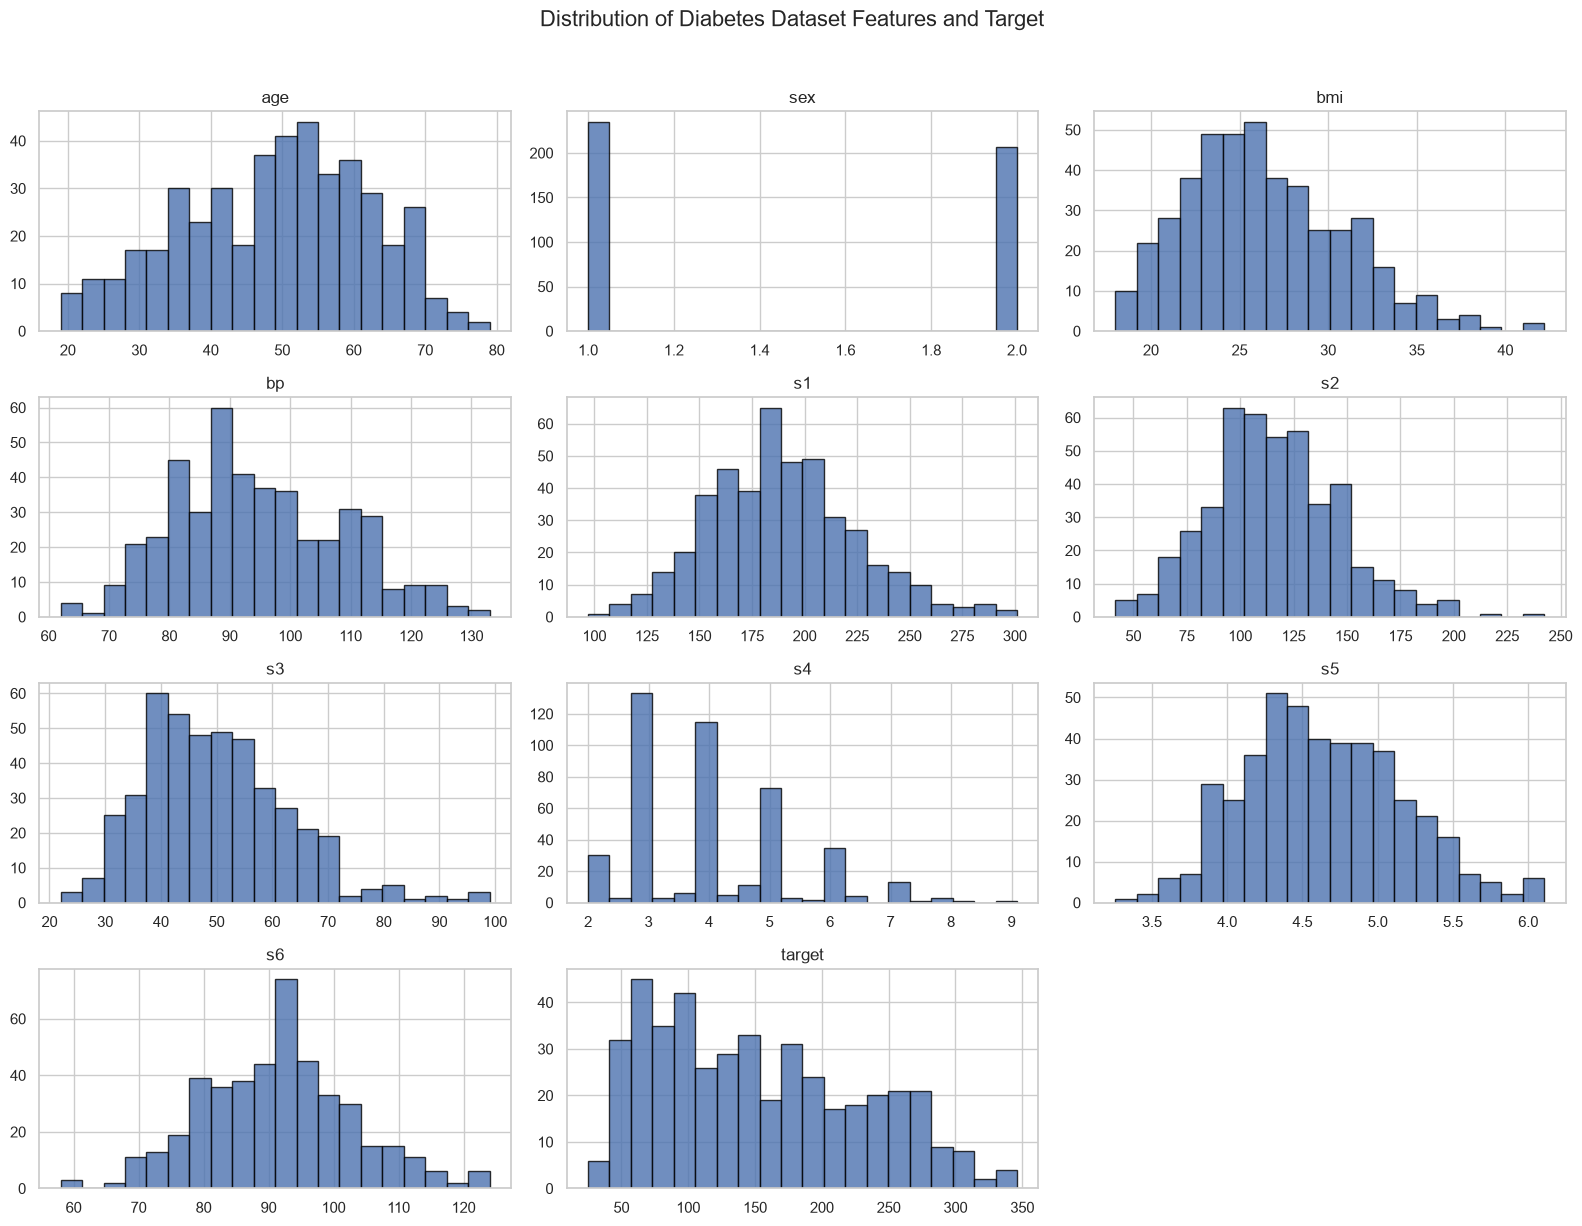

In [6]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

# Plot distributions of all features and the target
df.hist(
    bins=20,
    figsize=(16, 12),
    edgecolor="black",
    alpha=0.8
)

plt.suptitle(
    "Distribution of Diabetes Dataset Features and Target",
    fontsize=16,
    y=1.02
)

plt.tight_layout()
plt.show()


#### 1.3.4 Initial EDA Findings

The exploratory analysis provides the following observations:

**Dataset Completeness and Quality**
- The dataset contains 442 observations and 11 columns, including 10 predictors and one target variable.
- No missing values or duplicate records were detected.
- All columns are stored numerically. However, `sex` represents two encoded categories and should not be interpreted as a continuous measurement.

**Descriptive Statistics**
- The average patient age is 48.52 years, with ages ranging from 19 to 79.
- The average BMI is 26.38, with values ranging from 18.0 to 42.2.
- The diabetes progression target has a mean of 152.13, a median of 140.50, and a standard deviation of 77.09.
- The progression score ranges from 25 to 346, indicating substantial variation across patients.

**Distribution Analysis**
- BMI is concentrated around the mid-20s, with a right tail representing higher BMI observations.
- Several serum measurements show asymmetric or irregular distributions.
- The target has a skewness of 0.44, indicating a moderately right-skewed distribution.
- Potential extreme observations should be investigated before any data cleaning decisions.

**Implications for Modeling**

The dataset is sufficiently complete to proceed without immediate imputation or duplicate removal. The variation in the target indicates that predicting progression may be challenging. Relationships between individual features and the target must be examined further using scatter plots and correlation analysis.

These observations are descriptive and do not establish causal relationships.



#### 1.3.5 Scatter Plot Analysis

Scatter plots help visualize relationships between individual predictors and the diabetes progression target.

We examine age, BMI, blood pressure, and serum measurement `s5` to investigate whether higher or lower feature values are associated with changes in disease progression.

Linear trend lines are included to make general patterns easier to identify. These lines describe associations and do not establish causation.


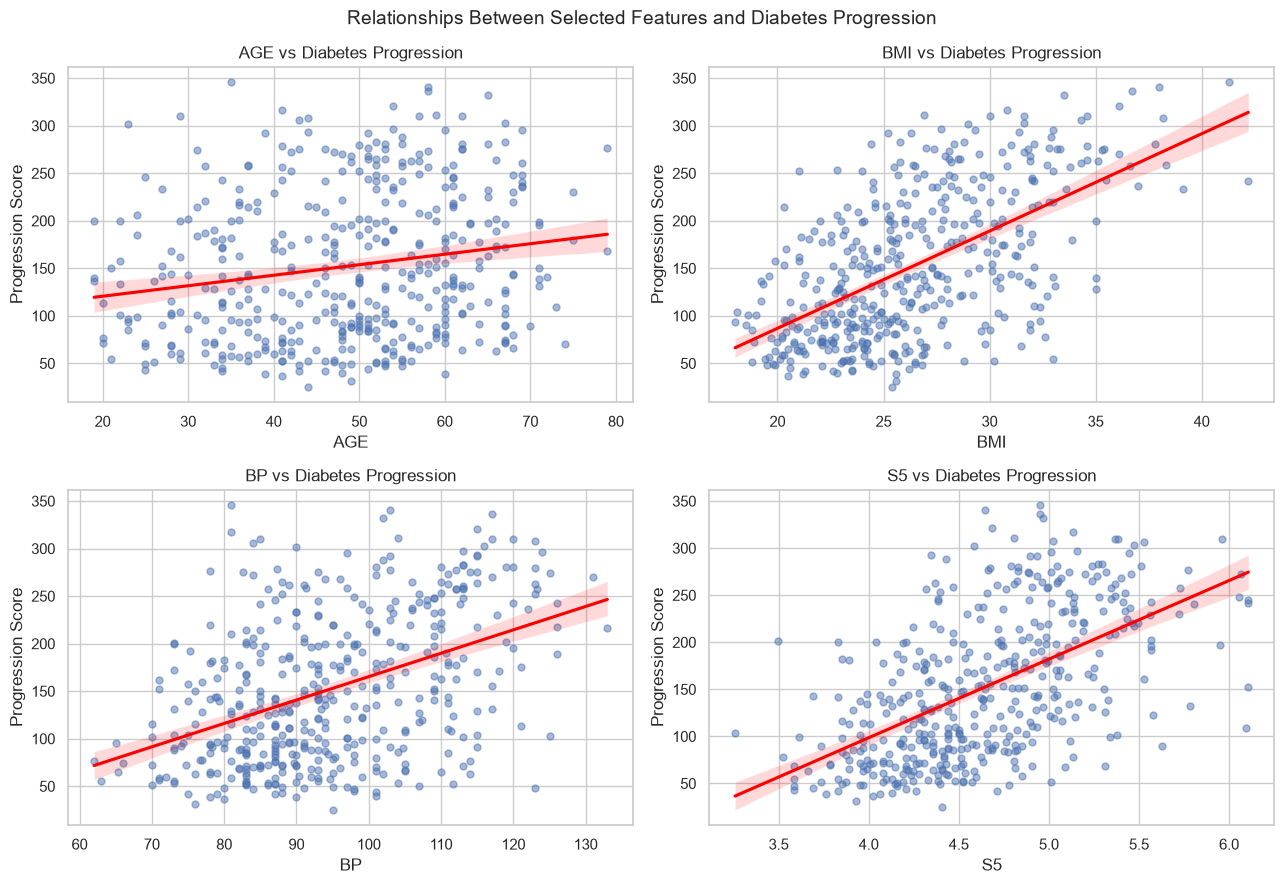

In [7]:
from src.diabetes_eda import DiabetesEDA

# Create an instance of the EDA class
eda = DiabetesEDA(df)

# Visualize relationships
eda.plot_scatter_relationships()


#### 1.3.6 Correlation Analysis

A Pearson correlation matrix is used to measure the strength and direction of linear relationships between numerical variables.

Correlation coefficients range from -1 to +1:

- **+1:** Perfect positive linear relationship.
- **0:** No linear relationship.
- **-1:** Perfect negative linear relationship.

We examine correlations with the target to identify potential predictors and correlations between features to identify possible multicollinearity.

Because `sex` is category-coded, its numerical correlation requires careful interpretation. Correlation does not imply causation.


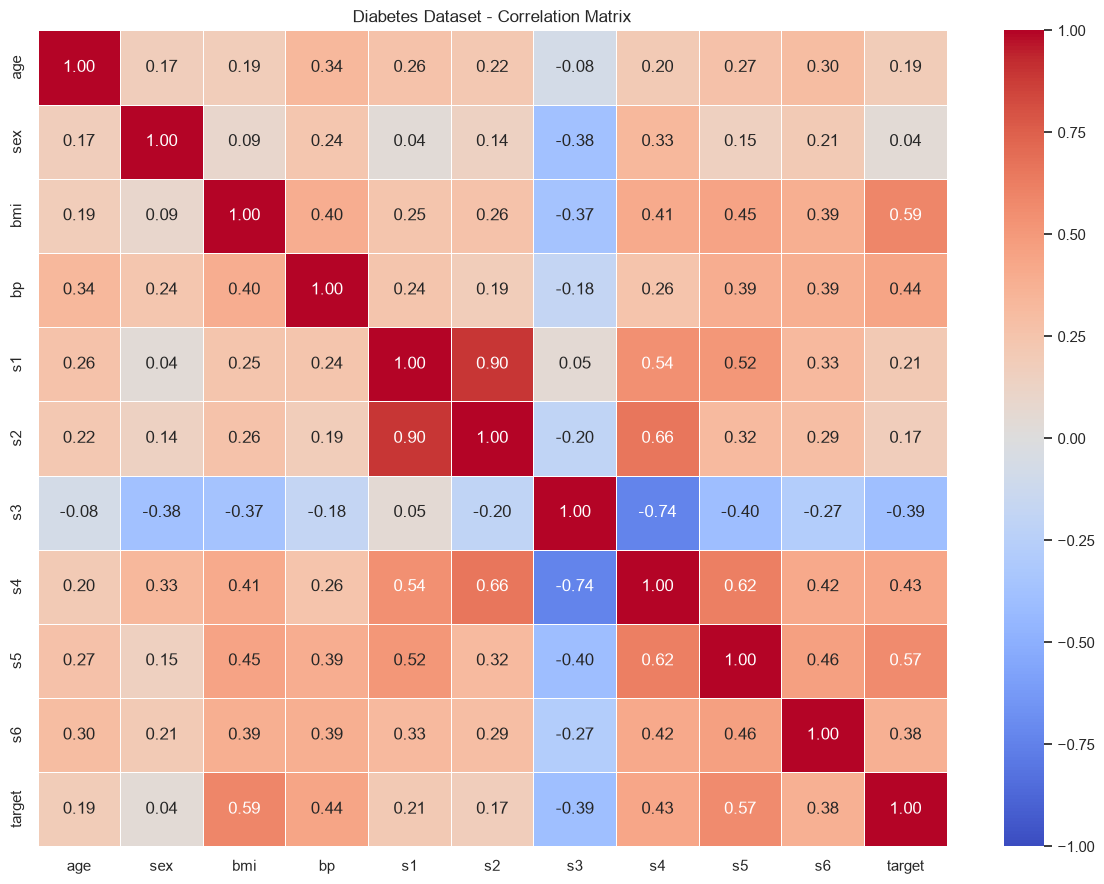

Feature Correlations with Diabetes Progression:


,Correlation with Target
bmi,0.586
s5,0.566
bp,0.441
s4,0.430
s6,0.382
s1,0.212
age,0.188
s2,0.174
sex,0.043
s3,-0.395


In [8]:
# Visualize correlation matrix
eda.plot_correlation_matrix()

# Rank correlations with diabetes progression
print("Feature Correlations with Diabetes Progression:")
display(
    eda.get_target_correlations()
    .to_frame(name="Correlation with Target")
    .round(3)
)


#### 1.3.7 Scatter Plot and Correlation Findings

**Scatter Plot Analysis**

The scatter plots reveal differences in how individual patient measurements relate to diabetes progression.

- **BMI:** Shows a clear positive relationship with the target. Patients with higher BMI values generally tend to have higher progression scores, although considerable variation remains.
- **S5:** Also demonstrates a noticeable positive association with disease progression.
- **Blood Pressure (BP):** Shows a moderate positive relationship, suggesting that blood pressure may contribute useful predictive information.
- **Age:** Has a relatively weak positive relationship with progression, indicating limited predictive ability when considered independently.

The considerable scatter around the trend lines suggests that relying on a single feature may not be sufficient for highly accurate predictions.

**Correlation Analysis**

The Pearson correlation matrix provides the following findings:

| Feature | Correlation with Target |
|---------|------------------------:|
| BMI | 0.586 |
| S5 | 0.566 |
| BP | 0.441 |
| S4 | 0.430 |
| S6 | 0.382 |
| S3 | -0.395 |
| Age | 0.188 |
| Sex | 0.043 |

BMI has the strongest positive linear correlation with diabetes progression, followed by S5. This supports using BMI for the univariate polynomial regression models in Part 2.

S3 has the strongest negative correlation with the target, indicating that higher S3 values tend to be associated with lower progression scores.

**Potential Multicollinearity**

The correlation matrix also reveals strong relationships between some predictors:

- S1 and S2: approximately 0.90
- S3 and S4: approximately -0.74

These relationships suggest potential multicollinearity, which can affect the stability and interpretation of regression coefficients.

Feature removal is not automatically necessary. We will consider these relationships when evaluating multivariate models in Part 3.

**Implications for Model Development**

1. BMI is an appropriate starting feature for univariate polynomial regression.
2. Additional features such as S5 and BP may improve predictive performance in multivariate models.
3. Weak individual correlation does not necessarily mean a feature has no predictive value when combined with others.
4. Training and validation results will be used to determine whether increasing model complexity improves generalization.

These results describe statistical associations rather than causal relationships.



#### 1.3.8 Outlier Detection Using the IQR Method

Potential outliers are examined using the Interquartile Range (IQR) method and boxplots.

The IQR is calculated as:

IQR = Q3 - Q1

Values below Q1 - 1.5 × IQR or above Q3 + 1.5 × IQR are flagged as potential outliers.

The encoded categorical feature `sex` is excluded from this analysis because the IQR method is not appropriate for its category codes.

The target variable is included for descriptive analysis but will not be used to remove observations automatically.

Outliers are not necessarily errors. Extreme patient measurements may represent legitimate clinical observations, so removal or modification requires additional justification.


IQR-Based Outlier Summary:


,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier %
Feature,,,,,,,
age,38.25,59.00,20.75,7.12,90.12,0,0.00
bmi,23.20,29.28,6.07,14.09,38.39,3,0.68
bp,84.00,105.00,21.00,52.50,136.50,0,0.00
s1,164.25,209.75,45.50,96.00,278.00,8,1.81
s2,96.05,134.50,38.45,38.37,192.18,7,1.58
s3,40.25,57.75,17.50,14.00,84.00,7,1.58
s4,3.00,5.00,2.00,0.00,8.00,2,0.45
s5,4.28,5.00,0.72,3.20,6.08,4,0.90
s6,83.25,98.00,14.75,61.12,120.12,9,2.04


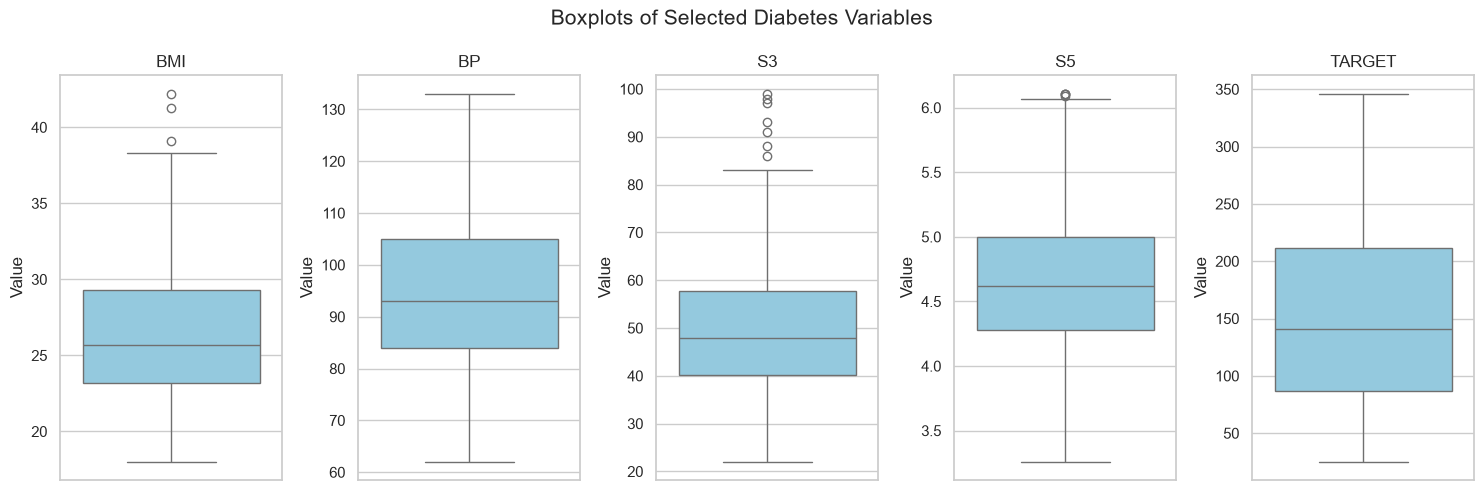

In [9]:

# Generate outlier report using our OOP class
outlier_summary = eda.outlier_report()

print("IQR-Based Outlier Summary:")
display(outlier_summary.round(2))

# Visualize selected variables
eda.plot_boxplots()



#### 1.3.9 Outlier Analysis Findings

The IQR method and boxplots identified several potential outliers in the diabetes dataset.

**Key Findings:**

- BMI contains 3 potential outliers (0.68%).
- S1 contains 8 potential outliers (1.81%).
- S2 and S3 each contain 7 potential outliers (1.58%).
- S4 contains 2 potential outliers (0.45%).
- S5 contains 4 potential outliers (0.90%).
- S6 contains 9 potential outliers (2.04%).
- Age, blood pressure, and the target variable have no outliers under the 1.5 × IQR rule.

The boxplots confirm the presence of several unusually high measurements, particularly for BMI and S3.

However, statistical outliers do not necessarily represent incorrect data. These observations may reflect genuine differences between patients.

Since no evidence of measurement errors has been identified, the outliers will be retained. Their possible influence on model performance will be considered during evaluation.

**Conclusion:** No automatic outlier removal or capping will be performed.



### 1.4 Data Cleaning and Preprocessing Decisions

Before model development, the dataset was examined for missing values, duplicated records, inconsistent data types, and potential outliers.

**Data Quality Assessment:**

| Check | Result | Decision |
|-------|--------|----------|
| Missing values | 0 | No imputation required |
| Duplicate records | 0 | No duplicates to remove |
| Data types | All numeric | No type conversion required |
| Encoded categorical feature | Sex (1 and 2) | Retain binary encoding |
| Potential outliers | Identified in several features | Retain observations |
| Target variable | Continuous numerical score | No target transformation required |

**Cleaning Decisions:**

The dataset is complete and does not require missing-value imputation or duplicate removal.

Although the IQR method identified some extreme observations, these values cannot be assumed to be errors. Therefore, all 442 patient records will be preserved.

The `sex` feature is represented using two numerical codes. Its existing binary encoding will be retained, while recognizing that its values represent categories rather than a continuous quantity.

Feature scaling will be applied within appropriate model pipelines, particularly for distance-based models such as KNN. Any fitted preprocessing transformations will be learned from the training set only to prevent data leakage.

**Final Decision:**

No records or features will be removed during the initial cleaning stage. The original feature values will be retained for model development, and the effects of model complexity and extreme observations will be considered during evaluation.


In [10]:
# Create a clean working copy without modifying the original data
df_clean = df.copy()

# Verify data integrity
assert df_clean.isna().sum().sum() == 0, "Missing values detected"
assert df_clean.duplicated().sum() == 0, "Duplicate records detected"
assert df_clean.shape == df.shape, "Dataset shape changed unexpectedly"

print("Data cleaning verification successful!")
print("Original dataset shape:", df.shape)
print("Clean dataset shape:", df_clean.shape)
print("Missing values:", df_clean.isna().sum().sum())
print("Duplicate records:", df_clean.duplicated().sum())
print("All original observations retained:", len(df_clean) == len(df))

Data cleaning verification successful!
Original dataset shape: (442, 11)
Clean dataset shape: (442, 11)
Missing values: 0
Duplicate records: 0
All original observations retained: True



### 1.5 Train, Validation, and Test Split

The cleaned dataset is divided into three mutually exclusive subsets to support model development and fair evaluation.

**Dataset Split:**

- **Training Set (75%):** Used to fit model parameters.
- **Validation Set (10%):** Used to compare models, select hyperparameters, and identify the best-performing configuration.
- **Test Set (15%):** Reserved for final evaluation after model selection.

The splitting process uses `train_test_split()` from Scikit-Learn with `random_state=42` to ensure reproducibility.

Since the dataset contains 442 observations, the split percentages are approximated using whole numbers of patient records.

The same split will be reused across Parts 2 and 3 to ensure consistent model comparisons.

Any preprocessing that learns parameters from data, such as feature scaling, will be fitted using the training set only. The test set will not be used for model selection or hyperparameter tuning.


In [11]:

from src.data_preparation import DiabetesDataPreparation

# Initialize our OOP data preparation class
data_preparation = DiabetesDataPreparation(
    dataframe=df_clean,
    random_state=42
)

# Perform the required split
splits = data_preparation.split_data()

X_train = splits["X_train"]
X_val = splits["X_val"]
X_test = splits["X_test"]

y_train = splits["y_train"]
y_val = splits["y_val"]
y_test = splits["y_test"]

# Summarize the split
split_summary = pd.DataFrame({
    "Dataset": ["Training", "Validation", "Test", "Total"],
    "Samples": [
        len(X_train),
        len(X_val),
        len(X_test),
        len(df_clean)
    ],
    "Percentage": [
        len(X_train) / len(df_clean) * 100,
        len(X_val) / len(df_clean) * 100,
        len(X_test) / len(df_clean) * 100,
        100.0
    ]
})

print("Train / Validation / Test Split:")
display(split_summary.round(2))

print("\nFeature and target shapes:")
print("X_train:", X_train.shape, "| y_train:", y_train.shape)
print("X_val:  ", X_val.shape, "| y_val:  ", y_val.shape)
print("X_test: ", X_test.shape, "| y_test:", y_test.shape)


Train / Validation / Test Split:


,Dataset,Samples,Percentage
0,Training,332,75.11
1,Validation,44,9.95
2,Test,66,14.93
3,Total,442,100.00



Feature and target shapes:
X_train: (332, 10) | y_train: (332,)
X_val:   (44, 10) | y_val:   (44,)
X_test:  (66, 10) | y_test: (66,)


In [12]:

# Verify that no patient appears in multiple sets
train_indices = set(X_train.index)
val_indices = set(X_val.index)
test_indices = set(X_test.index)

assert train_indices.isdisjoint(val_indices)
assert train_indices.isdisjoint(test_indices)
assert val_indices.isdisjoint(test_indices)

# Verify every original observation is included
all_indices = train_indices | val_indices | test_indices

assert all_indices == set(df_clean.index)

# Verify features and targets remain aligned
assert X_train.index.equals(y_train.index)
assert X_val.index.equals(y_val.index)
assert X_test.index.equals(y_test.index)

print("Data split verification successful!")
print("No overlapping observations: PASS")
print("All 442 observations accounted for: PASS")
print("Features and targets correctly aligned: PASS")


Data split verification successful!
No overlapping observations: PASS
All 442 observations accounted for: PASS
Features and targets correctly aligned: PASS



### 1.6 Part 1 Summary

In Part 1, we loaded and explored the Scikit-Learn Diabetes dataset containing 442 patients, 10 predictors, and a continuous diabetes progression target.

Exploratory Data Analysis included descriptive statistics, histograms, scatter plots, a correlation matrix, and IQR-based outlier detection.

BMI and S5 demonstrated the strongest positive correlations with the target, while S3 had a negative correlation. Strong relationships between certain predictors also suggested potential multicollinearity.

Data quality checks identified no missing values or duplicate observations. Although several potential outliers were detected, they were retained because no evidence indicated that they were erroneous.

The dataset was divided into approximately 75% training, 10% validation, and 15% testing using a reproducible random split.

The training and validation sets will support model development and selection, while the test set will remain reserved for final evaluation.

Part 2 will investigate univariate polynomial regression models of degrees 0 through 5 using BMI as the predictor.



---

## Part 2: Univariate Polynomial Regression Using BMI

### 2.1 Model Development

In this part, six polynomial regression models with degrees ranging from 0 to 5 are trained to predict diabetes progression using only BMI.

The objective is to investigate how polynomial complexity affects model performance and generalization.

- Degree 0 represents a constant baseline prediction.
- Degree 1 represents simple linear regression.
- Degrees 2 through 5 introduce increasingly flexible nonlinear relationships.

Each model is trained on the same training dataset and evaluated using the same validation dataset.

A Scikit-Learn Pipeline combines feature scaling, polynomial feature generation, and linear regression. Scaling is learned from training data only to avoid data leakage.

The models will be evaluated using R², MAE, and MAPE. Validation results will be used for model selection, while the test set will remain untouched until the best model is chosen.


In [13]:
from src.univariate_polynomial import UnivariatePolynomialRegression

# Initialize our OOP polynomial regression class
poly_models = UnivariatePolynomialRegression(
    X_train=X_train,
    y_train=y_train,
    X_val=X_val,
    y_val=y_val
)

# Train polynomial models of degrees 0 through 5
trained_models = poly_models.train_models()

print("Polynomial regression training completed!")
print("Total models trained:", len(trained_models))
print("Polynomial degrees:", list(trained_models.keys()))

Polynomial regression training completed!
Total models trained: 6
Polynomial degrees: [0, 1, 2, 3, 4, 5]



### 2.2 Training and Validation Model Comparison

The six polynomial regression models are evaluated using the following metrics:

- **R²:** Measures how well the model explains variation in the target. Higher values are generally better.
- **MAE:** Measures the average absolute difference between actual and predicted progression scores. Lower values are better.
- **MAPE:** Measures the average absolute percentage prediction error. Lower values are better.

Training and validation results are reported separately to help identify underfitting, overfitting, and the effect of increasing polynomial degree.

The validation set will be used to select the best-performing model before final testing.


In [14]:
# Compare training and validation results
polynomial_results = poly_models.compare_models()

print("Polynomial Regression Model Comparison:")
display(polynomial_results.round(3))

Polynomial Regression Model Comparison:


,Degree,Train R2,Validation R2,Train MAE,Validation MAE,Train MAPE (%),Validation MAPE (%)
0,0,0.000,-0.069,65.072,71.503,61.848,59.148
1,1,0.334,0.522,51.638,47.539,47.762,40.929
2,2,0.334,0.523,51.620,47.232,47.748,40.742
3,3,0.334,0.520,51.651,47.300,47.797,40.904
4,4,0.337,0.506,51.517,48.622,47.520,40.949
5,5,0.341,0.449,51.237,50.287,47.403,41.172



### 2.3 Model Comparison and Selection

Six polynomial regression models, with degrees 0 through 5, were trained using BMI as the only predictor.

**Key Findings:**

1. **Degree 0:** The baseline model achieved a validation R² of -0.069 and an MAE of 71.503. Its constant predictions do not capture the relationship between BMI and disease progression.

2. **Degree 1:** Linear regression significantly improved performance, achieving a validation R² of 0.522 and MAE of 47.539.

3. **Degree 2:** The quadratic model achieved the best validation performance:
   - R²: 0.523
   - MAE: 47.232
   - MAPE: 40.742%

4. **Degrees 3–5:** Increasing polynomial complexity did not improve validation performance. Degree 5 achieved a slightly higher training R² than Degree 2, but its validation R² decreased to 0.449. This suggests that additional complexity may reduce generalization.

**Selected Model: Degree 2 Polynomial Regression**

Degree 2 is selected because it achieved the highest validation R² and the lowest validation MAE and MAPE.

However, its improvement over Degree 1 is small. Therefore, the additional complexity provides only a marginal benefit over ordinary linear regression.

The validation R² of 0.523 indicates that the selected model explains approximately 52.3% of the variation in diabetes progression within the validation set.

The remaining unexplained variation suggests that BMI alone is insufficient for highly accurate predictions.

The selected model will now be evaluated once on the previously unseen test set.



### 2.4 Final Evaluation on the Test Set

After selecting the Degree 2 polynomial regression model using validation performance, the model is evaluated on the previously unseen test set.

The test set contains 66 observations, representing approximately 15% of the original dataset.

The model was fitted using the training data only. The validation set was used for model selection, and the test set was reserved for final evaluation.

The same three metrics are calculated: R², MAE, and MAPE.

This evaluation provides an estimate of how well the selected model generalizes to unseen observations.


In [15]:

# Select the best model based on validation R2
best_index = polynomial_results["Validation R2"].idxmax()

best_degree = int(
    polynomial_results.loc[best_index, "Degree"]
)

best_model = trained_models[best_degree]

print("Selected Polynomial Degree:", best_degree)

# Use only BMI for the univariate model
X_test_bmi = X_test[["bmi"]].copy()

# Predict unseen test observations
y_test_pred = best_model.predict(X_test_bmi)

# Calculate test metrics using our OOP class
test_metrics = poly_models.calculate_metrics(
    y_test,
    y_test_pred
)

# Create a professional results table
test_results = pd.DataFrame([{
    "Model": f"Polynomial Degree {best_degree}",
    "Test R2": test_metrics["R2"],
    "Test MAE": test_metrics["MAE"],
    "Test MAPE (%)": test_metrics["MAPE (%)"]
}])

print("\nFinal Test Set Evaluation:")
display(test_results.round(3))


Selected Polynomial Degree: 2

Final Test Set Evaluation:


,Model,Test R2,Test MAE,Test MAPE (%)
0,Polynomial Degree 2,0.215,54.842,48.386



### 2.5 Test Set Performance Analysis

The selected Degree 2 polynomial regression model was evaluated on the previously unseen test set containing 66 observations.

**Test Results:**

- **R²:** 0.215
- **MAE:** 54.842
- **MAPE:** 48.386%

**Interpretation:**

The test R² of 0.215 indicates that the model explains approximately 21.5% of the variation in diabetes progression within the test set.

The MAE of 54.842 indicates that predictions differ from actual progression scores by approximately 54.84 units on average.

The MAPE of 48.386% indicates substantial relative prediction errors.

Compared with validation performance, the model's test R² decreased from 0.523 to 0.215, while MAE increased from 47.232 to 54.842.

This performance reduction suggests that the model does not generalize as well to the test observations as its validation results initially indicated.

Possible explanations include limited predictive information from BMI alone, variation between the relatively small data subsets, and relationships that a univariate quadratic model cannot capture.

However, these results alone do not establish overfitting.

The model was selected using validation performance only, and no modifications were made based on the test results.

**Conclusion:**

Although Degree 2 achieved the best validation performance among the six polynomial models, its test results demonstrate important predictive limitations. Additional patient features may help improve performance in Part 3.

The model is not sufficiently validated for clinical screening or medical decision-making.



### 2.6 Visualization of the Selected Polynomial Model

The selected Degree 2 polynomial regression model is visualized against the training, validation, and test datasets.

Three side-by-side scatter plots show the actual diabetes progression scores for each subset.

The red curve represents predictions from the same model trained exclusively on the training dataset. The model is not refitted using validation or test observations.

The plots share the same BMI and progression-score axes to support visual comparison.

This visualization helps assess how well the model captures the relationship between BMI and disease progression across unseen observations.


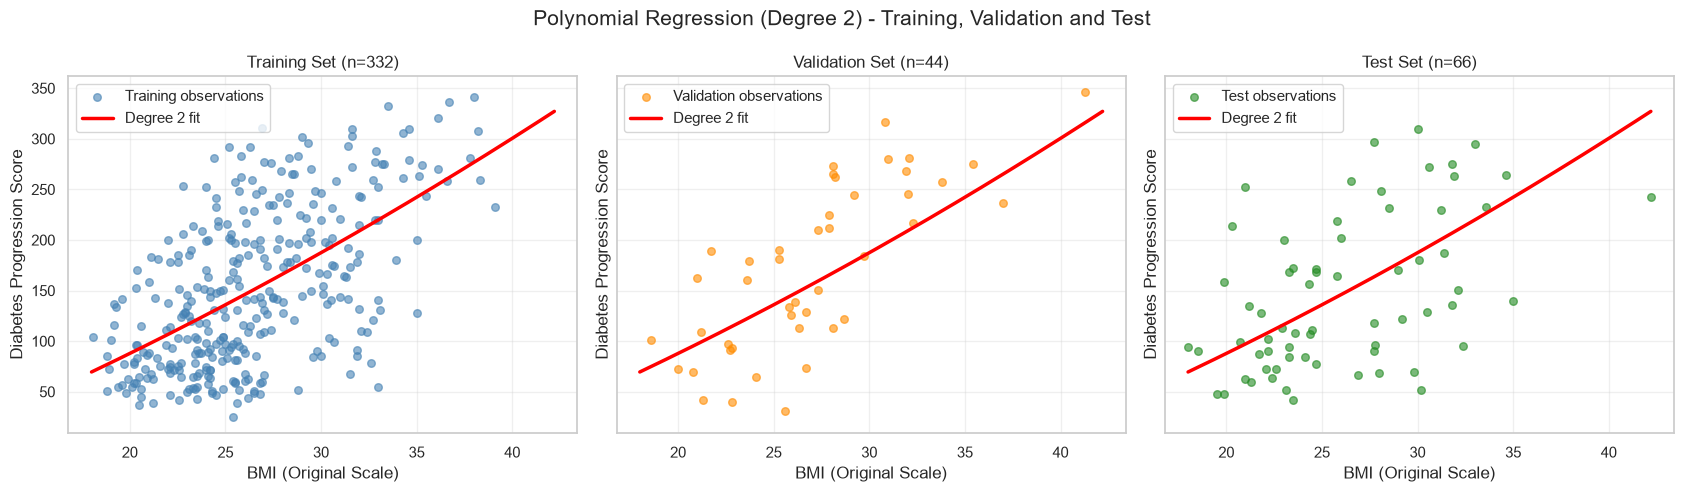

In [16]:
# Plot the trained Degree 2 model across all three datasets
poly_models.plot_model_across_splits(
    degree=best_degree,
    X_test=X_test,
    y_test=y_test
)


#### 2.6.1 Interpretation of the Polynomial Regression Plots

The Degree 2 polynomial model shows a positive relationship between BMI and predicted diabetes progression.

**Training Set:** The model captures the overall upward trend, but many observations are widely distributed around the fitted curve.

**Validation Set:** The predictions generally follow the observed trend. However, the considerable scatter indicates that BMI alone does not explain all variation in the target.

**Test Set:** Several observations differ substantially from the model's predictions, including patients with similar BMI values but very different progression scores. This is consistent with the lower test R² of 0.215.

The fitted curve shows relatively little curvature, which helps explain why the Degree 2 model only slightly outperformed the Degree 1 model during validation.

**Conclusion:** The visualization confirms that BMI has predictive value, but additional patient features may be needed to improve accuracy. The observed relationships are associations, not evidence of causation.



### 2.7 Equation of the Selected Polynomial Model

The selected Degree 2 polynomial regression model predicts diabetes progression using BMI and its squared term.

The general equation is:

\[
\hat{y} = b_0 + b_1(BMI) + b_2(BMI)^2
\]

Since the model pipeline includes StandardScaler, the fitted coefficients are transformed back to the original BMI scale before reporting the equation.

The coefficients are displayed to two decimal places for readability. Full-precision coefficients are retained for predictions and numerical calculations.


In [17]:

# Extract coefficients in original BMI units
coefficients = poly_models.get_quadratic_coefficients(
    degree=best_degree
)

b0 = coefficients["Intercept"]
b1 = coefficients["BMI"]
b2 = coefficients["BMI Squared"]

print("Best Model: Polynomial Degree", best_degree)

print("\nCoefficients (Original BMI Scale):")
for name, value in coefficients.items():
    print(f"{name}: {value:.6f}")

print("\nPolynomial Equation (2 Decimal Places):")
print(
    f"Predicted Progression = "
    f"{b0:.2f} {b1:+.2f} × BMI "
    f"{b2:+.2f} × BMI²"
)

# Verify that the original-scale equation agrees
# with the trained model's predictions
bmi_check = pd.DataFrame({
    "bmi": [20.0, 25.0, 30.0, 35.0]
})

pipeline_predictions = best_model.predict(bmi_check)

equation_predictions = (
    b0
    + b1 * bmi_check["bmi"].to_numpy()
    + b2 * bmi_check["bmi"].to_numpy() ** 2
)

import numpy as np

np.testing.assert_allclose(
    equation_predictions,
    pipeline_predictions,
    rtol=1e-10,
    atol=1e-8
)

print("\nEquation verification: PASS")


Best Model: Polynomial Degree 2

Coefficients (Original BMI Scale):
Intercept: -70.853178
BMI: 6.586365
BMI Squared: 0.067397

Polynomial Equation (2 Decimal Places):
Predicted Progression = -70.85 +6.59 × BMI +0.07 × BMI²

Equation verification: PASS



### 2.8 Predicting Diabetes Progression for a Selected BMI

To demonstrate how the trained model generates predictions, a BMI value of 30 is selected.

This value falls within the observed dataset range.

The trained Degree 2 polynomial model is used through its `predict()` method. The prediction is expressed in the target's progression-score units, not as a probability or a clinical diagnosis.


In [18]:
# Choose an example BMI
chosen_bmi = 30.0

# Predict through our OOP class
predicted_progression = poly_models.predict_for_bmi(
    degree=best_degree,
    bmi_value=chosen_bmi
)

print(f"Selected BMI: {chosen_bmi:.1f}")
print(
    f"Predicted Diabetes Progression: "
    f"{predicted_progression:.2f}"
)

Selected BMI: 30.0
Predicted Diabetes Progression: 187.39



**Precision Note:** The polynomial equation is displayed with two-decimal coefficients as requested. However, rounding the quadratic coefficient to two decimal places introduces noticeable prediction differences because BMI is squared. Therefore, a six-decimal version is also reported for more accurate interpretation. All predictions use the original full-precision trained model.



### 2.9 Number of Trainable Parameters

The number of trainable parameters in a univariate polynomial regression model depends on its polynomial degree.

For a polynomial of degree `d`, the number of trainable regression coefficients is:

\[
\text{Parameters} = d + 1
\]

The additional parameter represents the intercept (constant term).

For example:

- Degree 0 fits 1 parameter (constant).
- Degree 1 fits 2 parameters (constant and BMI).
- Degree 2 fits 3 parameters (constant, BMI, and BMI squared).
- Degree 5 fits 6 parameters (constant and powers of BMI through degree 5).

The Scikit-Learn `get_feature_names_out()` method is used to identify the polynomial terms.

In our pipeline, `PolynomialFeatures(include_bias=True)` generates the constant term, while `LinearRegression(fit_intercept=False)` prevents fitting an additional, redundant intercept.

The feature scaling statistics are not counted as trainable regression coefficients.

Higher-degree models contain more trainable parameters, allowing increased flexibility but potentially increasing the risk of overfitting.


In [19]:
# Display polynomial terms and trainable parameter counts
parameter_table = poly_models.parameter_summary()

print("Trainable Parameters for Polynomial Models:")
display(parameter_table)

# Verify expected counts
assert all(
    parameter_table["Trainable Parameters"]
    == parameter_table["Degree"] + 1
)

print("\nParameter count verification: PASS")

Trainable Parameters for Polynomial Models:


,Degree,Polynomial Terms,Trainable Parameters
0,0,1,1
1,1,"1, bmi_scaled",2
2,2,"1, bmi_scaled, bmi_scaled^2",3
3,3,"1, bmi_scaled, bmi_scaled^2, bmi_scaled^3",4
4,4,"1, bmi_scaled, bmi_scaled^2, bmi_scaled^3, bmi...",5
5,5,"1, bmi_scaled, bmi_scaled^2, bmi_scaled^3, bmi...",6



Parameter count verification: PASS



### 2.10 Error Analysis and Model Limitations

To investigate where the selected Degree 2 polynomial regression model fails, we examine individual prediction errors on the held-out test set.

The residual is defined as:

\[
Residual = Actual - Predicted
\]

A positive residual indicates that the model underestimated progression, while a negative residual indicates overestimation.

The analysis includes:

1. Actual versus predicted progression scores.
2. Residuals plotted against BMI.
3. The distribution of prediction residuals.
4. The five observations with the largest absolute prediction errors.
5. Summary statistics describing prediction accuracy and error direction.

These diagnostics help identify potential systematic errors, large prediction mistakes, and limitations of using BMI alone.

The test set is used only for final evaluation and descriptive error analysis. No model selection, tuning, or retraining will be performed using test results.


Test Error Summary:


,Measure,Value
0,Test observations,66.00
1,Mean signed residual,-2.37
2,Median absolute error,47.65
3,Maximum absolute error,154.82
4,Patients with absolute error > 50,32.00
5,Underpredicted observations,29.00
6,Overpredicted observations,37.00



Five Largest Prediction Errors:


,BMI,Actual,Predicted,Residual,Absolute Error,Absolute Percentage Error (%)
78,21.0,252.0,97.18,154.82,154.82,61.44
56,30.2,52.0,189.52,-137.52,137.52,264.47
113,27.7,297.0,163.30,133.70,133.70,45.02
218,20.3,214.0,90.62,123.38,123.38,57.65
9,30.0,310.0,187.39,122.61,122.61,39.55


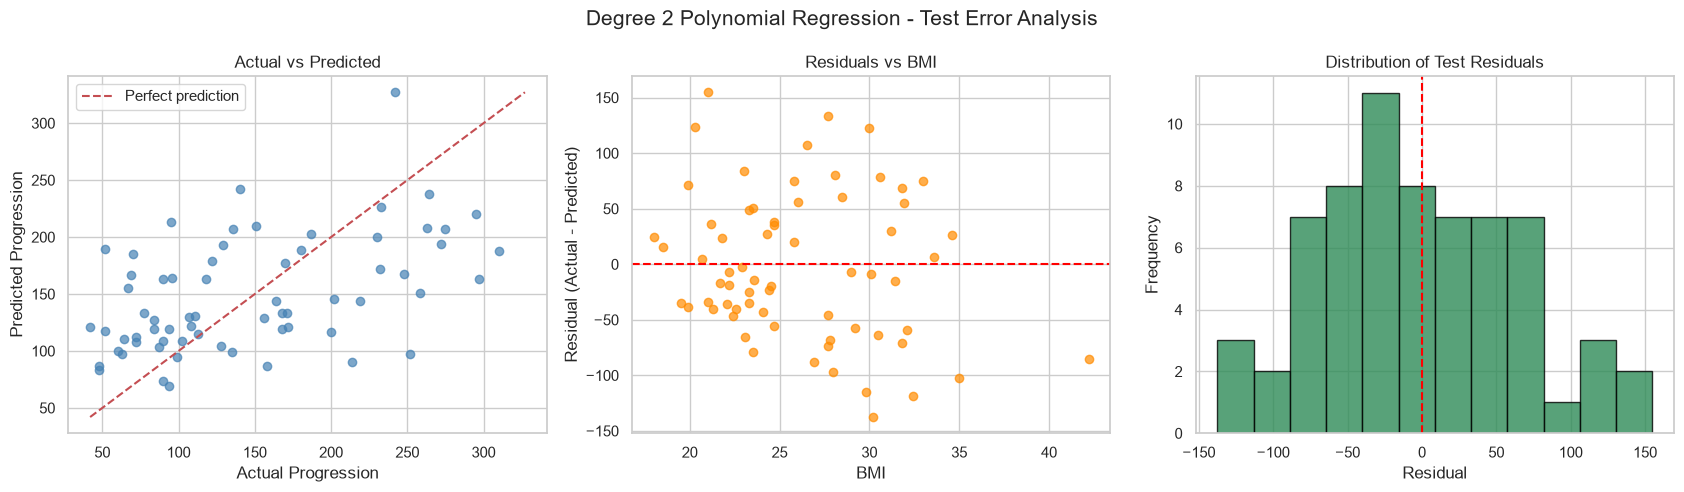

In [20]:

# Analyze the selected model's test predictions
test_errors = poly_models.get_test_error_report(
    degree=best_degree,
    X_test=X_test,
    y_test=y_test
)

# Summary of prediction errors
error_summary = pd.DataFrame({
    "Measure": [
        "Test observations",
        "Mean signed residual",
        "Median absolute error",
        "Maximum absolute error",
        "Patients with absolute error > 50",
        "Underpredicted observations",
        "Overpredicted observations"
    ],
    "Value": [
        len(test_errors),
        test_errors["Residual"].mean(),
        test_errors["Absolute Error"].median(),
        test_errors["Absolute Error"].max(),
        (test_errors["Absolute Error"] > 50).sum(),
        (test_errors["Residual"] > 0).sum(),
        (test_errors["Residual"] < 0).sum()
    ]
})

print("Test Error Summary:")
display(error_summary.round(2))

print("\nFive Largest Prediction Errors:")
display(
    test_errors.nlargest(
        5, "Absolute Error"
    ).round(2)
)

# Plot test error diagnostics
poly_models.plot_test_error_diagnostics(test_errors)



#### 2.10.1 Error Analysis Findings

The error analysis of the selected Degree 2 polynomial model reveals important limitations in its ability to predict diabetes progression.

**1. Magnitude of Prediction Errors**

The model achieved a test MAE of 54.842 and a MAPE of 48.386%.

Further analysis revealed:

- Mean signed residual: -2.37
- Median absolute error: 47.65
- Maximum absolute error: 154.82
- Observations with absolute error greater than 50: 32 out of 66 (48.5%)
- Underpredicted observations: 29
- Overpredicted observations: 37

Although the mean signed residual is close to zero, individual prediction errors remain substantial. Positive and negative residuals can cancel each other, so a small mean residual does not necessarily indicate accurate predictions.

**2. Where the Model Fails**

The five largest prediction errors reveal specific weaknesses:

| Patient Index | BMI | Actual | Predicted | Absolute Error |
|---|---:|---:|---:|---:|
| 78 | 21.0 | 252.00 | 97.18 | 154.82 |
| 56 | 30.2 | 52.00 | 189.52 | 137.52 |
| 113 | 27.7 | 297.00 | 163.30 | 133.70 |
| 218 | 20.3 | 214.00 | 90.62 | 123.38 |
| 9 | 30.0 | 310.00 | 187.39 | 122.61 |

The model substantially underpredicts several patients with high progression scores while overpredicting some patients with low progression scores.

For example, patient 78 has an actual progression score of 252 but receives a prediction of only 97.18.

Patient 56 has an actual progression score of 52, but the model predicts 189.52, producing an absolute percentage error of 264.47%.

These examples demonstrate that patients with similar BMI values can have substantially different progression outcomes.

**3. Diagnostic Plot Interpretation**

- **Actual vs Predicted:** Many observations are far from the perfect prediction line, indicating significant individual errors. Predictions cover a narrower range than actual values.
- **Residuals vs BMI:** Both positive and negative residuals occur throughout the observed BMI range. Several large errors indicate that BMI alone does not adequately explain patient outcomes.
- **Residual Distribution:** Errors appear on both sides of zero. The distribution includes substantial positive and negative residuals rather than being tightly concentrated around zero.

**4. Generalization**

Validation performance was stronger than test performance:

| Metric | Validation | Test |
|---|---:|---:|
| R² | 0.523 | 0.215 |
| MAE | 47.232 | 54.842 |
| MAPE | 40.742% | 48.386% |

The decline in performance suggests weaker generalization to the held-out test observations than the validation results indicated.

Possible contributing factors include limited information from BMI alone, differences between the relatively small data subsets, and patient-level variation that the polynomial model cannot explain.

These findings do not independently prove overfitting.

**5. Limitations of Percentage-Based Errors**

MAPE can become especially large when actual target values are small. For example, patient 56 has an actual progression score of 52 and an absolute percentage error of 264.47%.

Therefore, MAPE should be interpreted alongside MAE and R² rather than used as the only evaluation metric.

**Overall Finding**

The model captures a general positive association between BMI and diabetes progression but makes substantial errors for individual patients. The observed performance is not sufficient to support clinical decision-making.



### 2.11 Part 2 Conclusion

In Part 2, six univariate polynomial regression models (degrees 0 through 5) were developed to predict diabetes progression using BMI as the only input feature.

**Model Selection**

The Degree 2 polynomial regression model achieved the best validation performance:

- Validation R²: 0.523
- Validation MAE: 47.232
- Validation MAPE: 40.742%

The improvement over Degree 1 was small, suggesting that the relationship between BMI and progression is approximately linear over much of the observed range.

Increasing polynomial complexity beyond Degree 2 did not improve validation performance. In particular, Degree 5 achieved slightly better training performance but worse validation performance, suggesting that additional flexibility did not improve generalization.

**Final Test Performance**

The selected Degree 2 model achieved:

- Test R²: 0.215
- Test MAE: 54.842
- Test MAPE: 48.386%

The test R² indicates that approximately 21.5% of the variation in the held-out progression scores was explained by the model.

The reduction from validation to test performance highlights the importance of evaluating models on previously unseen data.

**Connections to Previous Workshops**

The Performance Metrics Classification workshop demonstrated that evaluation metrics must match the type of prediction problem. Unlike classification, where precision, recall, F1-score, and confusion matrices are used, this regression problem requires continuous-value metrics such as R², MAE, and MAPE.

The K-Nearest Neighbor workshop illustrated how model complexity and hyperparameter selection affect generalization. A similar principle applies to polynomial regression: increasing model complexity can improve training performance without improving performance on unseen observations.

The Logistic Regression Classifier workshop emphasized supervised learning, model fitting, and evaluation. It also highlighted the distinction between classification and regression. In this lab, the target is a continuous progression score, so regression models are appropriate for the primary prediction task.

**Model Limitations**

The selected model has several limitations:

1. BMI alone cannot capture all factors influencing diabetes progression.
2. Individual prediction errors are substantial, particularly for some patients with unusually high or low progression scores.
3. The dataset is relatively small, and the validation and test subsets contain only 44 and 66 observations, respectively.
4. The model captures statistical associations but does not establish causal relationships.
5. The model has not been clinically validated and should not be used independently for patient screening or treatment decisions.

**Final Conclusion**

The Degree 2 polynomial model was the strongest univariate model according to the validation metrics. However, its test results demonstrate limited predictive performance.

The analysis shows that selecting the best model from a group does not guarantee that the selected model is sufficiently accurate for practical use.

Part 3 will explore multivariate polynomial regression and non-parametric models to determine whether incorporating additional patient measurements improves predictive performance.
